# Figure 3 with the hybrid lookup-table decoder (no post-selection)

This notebook reruns the original Figure 3 simulations with the corrected code:

* **Decoder:** `HybridLUT`, with **no post-selection** (the original figure used the post-selected `BetterLUT2`):
  * the lookup table with memory from Ref. [Simakov2025] decodes every shot on which its two temporal preprocessing rules (looking one or two cycles ahead) agree;
  * the shots on which they disagree are decoded with Tesseract (search width 12) on the circuit's detector error model;
  * the fraction of fallback shots is reported. It is about $10^{-4}$ at low $p$ and becomes large near the crossing points and in long runs, so it must be stated in the paper.
* **Requirements:** `tesseract-decoder` (`pip install tesseract-decoder`) in addition to the earlier packages.
* **Noise model:**
  * depolarizing $p$ on the data once per cycle;
  * measurement flip $q = p$;
  * after each extra readout round, $r\,p$ on the data **and on syndrome qubits not yet measured**. Measured syndrome qubits are reset on demand and stay noiseless.
  * Here $r = 1$, which reproduces the original data noise ($p$ per measurement round).
* **Configurations:** $d = 5, 7, 9$, with $M = 1, 2, 3$ readout rounds. $k$ is the smallest number of measurement sites that gives $M$ rounds (Table 2 of the paper).
* **Sampling:**
  * 10 log-spaced $p$ from 0.1% to 0.8%;
  * for $M = 1$, 4 extra points with the same spacing up to about 2%, because its crossing point lies at the top of the main grid;
  * rounds $R = 1, 2, 4, 8, 16, 32, 50$;
  * each task runs until 1000 logical errors or 500,000 shots, in batches of 5000. A top-up section can add shots later.

**Analysis** (as in the Figure 3 cell of `plot_results_phenom.ipynb`):
* $\epsilon$ per cycle comes from the original fidelity fit, **using all rounds**, averaged over bases.
* The crossing point $p_c$ is the median of the crossings of adjacent distances (`fss_threshold.estimate_threshold`), **using all $p$ values**. The straight lines are the collapsed fit $\log\epsilon = a + b\,\log(p/p_c)\,d^{1/\nu}$, which meet at the star.
* Bootstrap error bars are shown on $\epsilon$ and on $p_c$.
* If no distances cross, the crossing-point estimate falls back to the middle of the $p$ range. In that case the table says `none` under crossings, and no star is drawn.

**Workflow:**
1. Run the Z basis, including the $M = 1$ extension.
2. Look at Figure 3 (Z only).
3. Run the X and Y bases, again including the $M = 1$ extension.
4. Plot the final Figure 3, averaged over X, Y, Z.
5. Optionally, top up the statistics and re-plot.

Every finished task is saved immediately, so interrupted runs resume where they stopped.

In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import collectorGlobal as cg
import lut_pipeline as lp

TEST_MODE = False

DISTANCES  = [5, 7, 9]
M_VALUES   = [1, 2, 3]
R_IDLE     = 1.0                 # r: idle noise r*p after each extra readout round
ANCILLAS   = 'waiting'           # r*p also on syndrome qubits not yet measured; reset ones are noiseless
start_val, end_val, num_points = 1e-3, 8e-3, 10
P_VALUES   = np.logspace(np.log10(start_val), np.log10(end_val), num=num_points)
# extra M = 1 points above the main grid, same log spacing: ~1.0, 1.3, 1.6, 2.0 %
P_EXTRA_M1 = P_VALUES[-1] * (P_VALUES[1] / P_VALUES[0]) ** np.arange(1, 5)
ROUNDS     = [1, 2, 4, 8, 16, 32, 50]
MAX_ERRORS = 1000
MAX_SHOTS  = 500_000
SHOTS_STEP = 5000
DECODER    = 'HybridLUT'          # BetterLUT + Tesseract fallback on disagreement shots (no post-selection)
WORKERS    = 8
N_BOOT     = 200
RESULTS_DIR = 'lut_results'

DROP_END_ROUNDS = False          # all rounds are used in the eps fit
DROP_END_P      = False          # all p values are used in the crossing-point fit

# p values left out of the analysis AND the plot (the data stay in the result files)
P_EXCLUDE = {1: P_EXTRA_M1[1:],      # M = 1: drop ~1.27, 1.6, 2.02 %
             2: [P_VALUES[-1:]],      # M = 2: drop 0.8 %
             3: [P_VALUES[-1:]]}      # M = 3: drop 0.8 %

if TEST_MODE:
    DISTANCES, M_VALUES = [5, 7], [1, 3]
    P_VALUES = np.logspace(np.log10(3e-3), np.log10(1.5e-2), 5)
    P_EXTRA_M1 = P_VALUES[-1] * (P_VALUES[1] / P_VALUES[0]) ** np.arange(1, 3)
    ROUNDS, MAX_ERRORS, MAX_SHOTS, SHOTS_STEP, N_BOOT, WORKERS = [1, 2, 4, 8], 50, 5000, 1000, 30, 2
    RESULTS_DIR = 'lut_results_TEST'

os.makedirs(RESULTS_DIR, exist_ok=True)
cg.set_lut_cache_dir(os.path.join(RESULTS_DIR, 'lookup_tables'))   # tables built once, shared by all workers
print('p (%):', np.round(100 * P_VALUES, 4))
print('extra M=1 p (%):', np.round(100 * P_EXTRA_M1, 4))
for d in DISTANCES:
    print(f'd={d}: k for M={M_VALUES} =', [lp.code_class(d).k_for_rounds(d, M) for M in M_VALUES])

p (%): [0.1    0.126  0.1587 0.2    0.252  0.3175 0.4    0.504  0.635  0.8   ]
extra M=1 p (%): [1.0079 1.2699 1.6    2.0159]
d=5: k for M=[1, 2, 3] = [13, 7, 5]
d=7: k for M=[1, 2, 3] = [21, 11, 7]
d=9: k for M=[1, 2, 3] = [29, 15, 10]


### Figure 3 plotting function
This uses the original encoding:
* colour for $d$, with the same colours as before;
* line style for $M$: solid, dashed and dotted;
* fainter lines for larger $M$;
* a star at each crossing point, with its label.

`XLIM`, `YLIM` and `LABEL_POS` (the label position for each $M$, in axes fraction) can be adjusted. The break-even line is left out.

In [3]:
DISTANCE_COLORS = {5: '#1B4B82', 7: '#4C9A5B', 9: '#C0392B'}
M_LINESTYLES    = {1: '-', 2: '--', 3: ':'}
M_ALPHAS        = {1: 1.0, 2: 0.7, 3: 0.6}
# Star labels: each label is placed at a fixed position in AXES FRACTION (0 = left/bottom, 1 = right/top),
# so it can never leave the frame; a thin line connects it to its star.
# (x, y, ha, va): ha/va choose which corner of the label box sits at (x, y). Move a label by changing x, y.
LABEL_POS       = {1: (0.97, 0.70, 'right', 'center'),   # right edge, below the M = 1 crossing
                   2: (0.42, 0.97, 'left', 'top'),       # top, above the M = 2 star
                   3: (0.30, 0.87, 'left', 'top')}       # top left (legend moved to the lower right)
LABEL_FONTSIZE  = 10
LABEL_SYMBOL    = 'c'                # label text p_c^{(M)}, as in the paper
LEGEND_LOC      = 'lower right'
# x-axis tick labels: list of p values to label (None = matplotlib default), and the label style:
# 'sci' -> 2x10^-3, 'percent' -> 0.2%, 'plain' -> 0.002
X_TICKS         = [1e-3, 2e-3, 3e-3, 5e-3, 1e-2]
X_TICK_STYLE    = 'sci'

def _xtick_label(x, _pos=None):
    if X_TICK_STYLE == 'percent':
        return f'{100 * x:g}%'
    if X_TICK_STYLE == 'plain':
        return f'{x:g}'
    e = int(np.floor(np.log10(x) + 1e-9)); m = x / 10**e
    return f'$10^{{{e}}}$' if abs(m - 1) < 1e-9 else f'${m:g}\\times10^{{{e}}}$'
XLIM, YLIM      = (1e-3, 1.1e-2), (1e-7, 1e-2)   # axis limits; None = automatic

def figure3(res_by_M, M_to_plot, fname=None, title=None):
    fig, ax = plt.subplots(1, 1, figsize=(8, 5.5))
    for M in M_to_plot:
        res, alpha, ls = res_by_M[M], M_ALPHAS[M], M_LINESTYLES[M]
        for d in DISTANCES:
            ok = (res['eps'][d] > 1e-9) & (res['n_err'][d] > 0)     # hide points with no logical errors
            yerr = res['eps_err'][d][ok] if res['eps_err'][d] is not None else None
            ax.errorbar(res['p'][ok], res['eps'][d][ok], yerr=yerr, fmt='o', ms=5, color=DISTANCE_COLORS[d],
                        alpha=alpha, elinewidth=1, capsize=2)
            p_fine = np.geomspace(res['th']['p_fit'].min(), res['th']['p_fit'].max(), 300)
            ax.plot(p_fine, lp.line_curve(res, d, p_fine), linestyle=ls, color=DISTANCE_COLORS[d], alpha=alpha,
                    linewidth=1.8)
        th = res['th']
        if not th['found']:
            # the crossing-point estimate falls back to the middle of the p range when nothing crosses: no star
            print(f'M={M}: no crossing in the fitted p range -> no star drawn')
            continue
        ax.plot(th['p_th'], th['pL_th'], marker='*', markersize=20, color='black', markeredgecolor='white',
                markeredgewidth=1.0, alpha=alpha, zorder=12)
        lx, ly, lha, lva = LABEL_POS[M]
        ax.annotate(f"$p^{{({M})}}_{{{LABEL_SYMBOL}}}={lp.fmt_sig(100 * th['p_th'], 2)}\\%$", xy=(th['p_th'], th['pL_th']),
                    xytext=(lx, ly), textcoords='axes fraction', ha=lha, va=lva, fontsize=LABEL_FONTSIZE, color='black',
                    alpha=min(alpha + 0.3, 1.0),
                    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='black', alpha=0.75 * alpha + 0.25, linewidth=0.6),
                    arrowprops=dict(arrowstyle='-', color='black', alpha=alpha, linewidth=0.8), zorder=13)
    if XLIM is not None: ax.set_xlim(XLIM)
    if YLIM is not None: ax.set_ylim(YLIM)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.minorticks_on()
    if X_TICKS is not None:
        from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
        ax.xaxis.set_major_locator(FixedLocator(X_TICKS))
        ax.xaxis.set_major_formatter(FuncFormatter(_xtick_label))
        ax.xaxis.set_minor_formatter(NullFormatter())        # keep minor ticks, but unlabeled
    ax.tick_params(axis='both', which='major', labelsize=13); ax.tick_params(axis='x', which='minor', labelsize=13)
    ax.legend(handles=[Line2D([0], [0], color=DISTANCE_COLORS[d], linestyle='-', linewidth=2.5, label=f'$d={d}$')
                       for d in DISTANCES], loc=LEGEND_LOC, fontsize=12, frameon=True)
    if title: ax.set_title(title, fontsize=10)
    if fname: plt.savefig(os.path.join(RESULTS_DIR, fname), bbox_inches='tight')
    plt.show()

def analyse_all(bases, drop_end_rounds, drop_end_p):
    table = lp.collect_table(M_VALUES, R_IDLE, DISTANCES, bases, RESULTS_DIR, decoder=DECODER, ancillas=ANCILLAS)
    for M, p_drop in P_EXCLUDE.items():             # remove excluded p before any fitting or plotting
        for d in table.get(M, {}):
            for b in table[M][d]:
                table[M][d][b] = {p: v for p, v in table[M][d][b].items()
                                  if not np.any(np.isclose(p, p_drop, rtol=1e-6))}
    return {M: lp.analyse(table[M], DISTANCES, bases, drop_end_rounds, drop_end_p, N_BOOT, seed=0) for M in M_VALUES}

def crossing_table(res_by_M):
    rows = []
    for M, res in res_by_M.items():
        th = res['th']
        rows.append(dict(M=M, p_c_percent=100 * th['p_th'], err_percent=100 * res['p_th_err'],
                         ci68_percent=f"[{100*res['p_th_ci68'][0]:.3f}, {100*res['p_th_ci68'][1]:.3f}]",
                         nu=th['nu'], crossings_percent=', '.join(f'{100*c:.3f}' for c in th['crossings']) or 'none',
                         boot_found=res['boot_found'],
                         points_below_100_errors=int(sum(np.sum(res['n_err'][d] < 100) for d in DISTANCES))))
    df = pd.DataFrame(rows)
    df['M1_over_M'] = float(df.loc[df.M == 1, 'p_c_percent'].iloc[0]) / df['p_c_percent'] if (df.M == 1).any() else np.nan
    return df

def tasks_for(bases):
    # main grid for every M, plus the extra M = 1 points
    return (lp.build_tasks(M_VALUES, R_IDLE, DISTANCES, bases, P_VALUES, ROUNDS, RESULTS_DIR, ANCILLAS)
            + lp.build_tasks([1], R_IDLE, DISTANCES, bases, P_EXTRA_M1, ROUNDS, RESULTS_DIR, ANCILLAS))

def show_points_used(res_by_M):
    for M, res in res_by_M.items():
        print(f'M={M}: {len(res["p"])} p values used, {100*res["p"].min():.3f}-{100*res["p"].max():.3f} %')

def show_fallback(bases):
    # fraction of shots decoded by the Tesseract fallback, per (M, d, p)
    df = pd.DataFrame(lp.fallback_table(M_VALUES, R_IDLE, DISTANCES, bases, RESULTS_DIR, decoder=DECODER, ancillas=ANCILLAS))
    if df.empty:
        print('no fallback data'); return
    piv = df.pivot_table(index=['M', 'd'], columns='p_percent', values='fallback_fraction')
    piv.columns = [f'{c:.3g}%' for c in piv.columns]
    print('fraction of shots decoded by the fallback (pooled over rounds and bases):')
    display(piv.apply(lambda col: col.map(lambda v: f'{v:.1e}')))   # works on old and new pandas
    piv2 = df.pivot_table(index=['M', 'd'], columns='p_percent', values='fallback_fraction_longest_run')
    piv2.columns = [f'{c:.3g}%' for c in piv2.columns]
    print(f'same, in the longest runs only (R = {int(df.longest_run.max())}), where it is largest:')
    display(piv2.apply(lambda col: col.map(lambda v: f'{v:.1e}')))   # works on old and new pandas


## 1. Z basis
This runs the main grid for every $M$, plus the extra $M = 1$ points.

In [24]:
lp.run_tasks(tasks_for(['Z']), MAX_SHOTS, MAX_ERRORS, WORKERS, shots_step=SHOTS_STEP, decoder=DECODER)

714 tasks, 714 already done, 0 to run


### Figure 3, Z basis
Choose which $M$ to show with `M_TO_PLOT`. The first lines printed give the $p$ range used for each $M$. $M = 1$ should show 11 values, up to about 1.0%, and $M = 2, 3$ should show 9, up to about 0.64%.

In [ ]:
M_TO_PLOT = M_VALUES
res_Z = analyse_all(['Z'], DROP_END_ROUNDS, DROP_END_P)
show_points_used(res_Z)
display(crossing_table(res_Z).round(4))
figure3(res_Z, M_TO_PLOT, 'figure3_Z.pdf')
show_fallback(['Z'])

## 2. X and Y bases
Run this if the Z results look good. It also runs the extra $M = 1$ points for X and Y. Without them, those points would be dropped from the basis average.

In [ ]:
lp.run_tasks(tasks_for(['X', 'Y']), MAX_SHOTS, MAX_ERRORS, WORKERS, shots_step=SHOTS_STEP, decoder=DECODER)

## 3. Final Figure 3, averaged over X, Y, Z
Check that $M = 1$ uses 11 $p$ values and $M = 2, 3$ use 9. If $M = 1$ shows fewer, the X/Y run is not finished.

M=1: 11 p values used, 0.100-1.008 %
M=2: 9 p values used, 0.100-0.635 %
M=3: 9 p values used, 0.100-0.635 %


,M,p_c_percent,err_percent,ci68_percent,nu,crossings_percent,boot_found,points_below_100_errors,M1_over_M
0,1,0.7686,0.0088,"[0.762, 0.777]",1.2150,"0.861, 0.676",200/200,5,1.0000
1,2,0.4653,0.0142,"[0.453, 0.476]",1.3510,"0.527, 0.404",200/200,0,1.6519
2,3,0.3319,0.0097,"[0.323, 0.344]",1.4459,"0.384, 0.280",200/200,0,2.3155


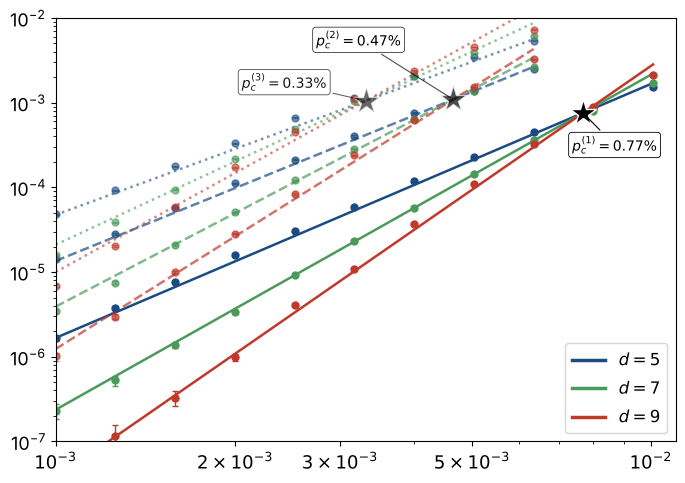

fraction of shots decoded by the fallback (pooled over rounds and bases):


0.1%   0.126%   0.159%     0.2%   0.252%   0.317%     0.4%   0.504%  \
M d                                                                           
1 5  5.8e-05  1.0e-04  2.2e-04  4.2e-04  8.5e-04  1.5e-03  2.1e-03  2.8e-03   
  7  2.7e-05  5.9e-05  1.3e-04  2.9e-04  6.7e-04  1.5e-03  3.1e-03  4.5e-03   
  9  3.2e-05  6.6e-05  1.4e-04  2.9e-04  6.7e-04  1.6e-03  3.9e-03  6.2e-03   
2 5  3.9e-04  7.7e-04  1.3e-03  2.0e-03  2.6e-03  3.4e-03  4.1e-03  5.5e-03   
  7  2.1e-04  4.9e-04  1.1e-03  2.5e-03  3.8e-03  5.0e-03  6.2e-03  7.4e-03   
  9  1.8e-04  4.2e-04  1.0e-03  2.7e-03  5.2e-03  6.8e-03  8.1e-03  8.5e-03   
3 5  1.1e-03  1.7e-03  2.4e-03  3.2e-03  3.9e-03  4.9e-03  6.3e-03  7.8e-03   
  7  8.7e-04  2.0e-03  3.3e-03  4.5e-03  5.7e-03  7.0e-03  9.1e-03  9.6e-03   
  9  7.3e-04  1.9e-03  4.4e-03  6.1e-03  7.6e-03  8.7e-03  9.5e-03  1.1e-02   

      0.635%     0.8%    1.01%    1.27%     1.6%    2.02%  
M d                                                        
1 5  3.6e-03  4.5e-03  5.6e-03  6.6e-03  9.9e-03  1.2e-02  
  7  5.5e-03  6.6e-03  7.4e-03  9.0e-03  1.0e-02  1.1e-02  
  9  7.5e-03  8.3e-03  8.9e-03  9.4e-03  7.5e-03  7.5e-03  
2 5  6.1e-03  9.0e-03      nan      nan      nan      nan  
  7  8.6e-03  1.0e-02      nan      nan      nan      nan  
  9  1.0e-02  9.6e-03      nan      nan      nan      nan  
3 5  1.1e-02  1.2e-02      nan      nan      nan      nan  
  7  1.2e-02  1.3e-02      nan      nan      nan      nan  
  9  8.5e-03  1.1e-02      nan      nan      nan      nan

same, in the longest runs only (R = 50), where it is largest:


0.1%   0.126%   0.159%     0.2%   0.252%   0.317%     0.4%   0.504%  \
M d                                                                           
1 5  1.9e-04  3.7e-04  7.6e-04  1.5e-03  2.9e-03  5.8e-03  1.1e-02  2.2e-02   
  7  8.8e-05  2.2e-04  4.7e-04  1.0e-03  2.3e-03  5.4e-03  1.2e-02  2.8e-02   
  9  1.1e-04  2.4e-04  4.9e-04  1.0e-03  2.4e-03  5.7e-03  1.4e-02  3.5e-02   
2 5  1.3e-03  2.6e-03  5.2e-03  1.0e-02  1.9e-02  3.7e-02  6.6e-02  1.2e-01   
  7  7.5e-04  1.7e-03  4.1e-03  9.6e-03  2.2e-02  4.7e-02  9.6e-02  1.8e-01   
  9  6.1e-04  1.5e-03  3.8e-03  1.0e-02  2.5e-02  6.1e-02  1.3e-01  2.5e-01   
3 5  4.2e-03  8.3e-03  1.6e-02  3.1e-02  5.5e-02  9.8e-02  1.6e-01  2.4e-01   
  7  3.1e-03  7.1e-03  1.6e-02  3.6e-02  7.5e-02  1.4e-01  2.5e-01  3.6e-01   
  9  2.6e-03  6.9e-03  1.8e-02  4.4e-02  1.0e-01  2.0e-01  3.2e-01  4.3e-01   

      0.635%     0.8%    1.01%    1.27%     1.6%    2.02%  
M d                                                        
1 5  4.2e-02  7.7e-02  1.4e-01  2.2e-01  3.2e-01  4.0e-01  
  7  5.9e-02  1.2e-01  2.1e-01  3.3e-01  4.2e-01  4.7e-01  
  9  8.3e-02  1.7e-01  3.0e-01  4.2e-01  4.7e-01  4.7e-01  
2 5  1.9e-01  2.8e-01      nan      nan      nan      nan  
  7  2.9e-01  3.9e-01      nan      nan      nan      nan  
  9  3.7e-01  4.5e-01      nan      nan      nan      nan  
3 5  3.4e-01  4.2e-01      nan      nan      nan      nan  
  7  4.5e-01  4.8e-01      nan      nan      nan      nan  
  9  4.7e-01  4.8e-01      nan      nan      nan      nan

In [4]:
M_TO_PLOT = M_VALUES
res_XYZ = analyse_all(['X', 'Y', 'Z'], DROP_END_ROUNDS, DROP_END_P)
show_points_used(res_XYZ)
display(crossing_table(res_XYZ).round(4))
figure3(res_XYZ, M_TO_PLOT, 'figure3_XYZ.pdf')
show_fallback(['X', 'Y', 'Z'])

## 4. Optional: more statistics for all bases
This adds shots to every task until it reaches `NEW_MAX_ERRORS` errors or `NEW_MAX_SHOTS` shots **in total** (existing plus new). New results are appended to the same files and added together in the analysis. Tasks already at the new targets are skipped, and the cell can be interrupted and re-run.

Raising only `NEW_MAX_ERRORS` mostly improves the points near the crossings, and costs much less than also raising `NEW_MAX_SHOTS`: most of the run time goes into low-$p$ tasks that run to the shot cap. After the top-up, re-run the Section 3 cell.

In [ ]:
NEW_MAX_ERRORS = 3000          # TOTAL per task, existing + new
NEW_MAX_SHOTS  = 1_500_000     # TOTAL per task, existing + new
lp.topup_tasks(tasks_for(['X', 'Y', 'Z']), NEW_MAX_SHOTS, NEW_MAX_ERRORS, WORKERS, shots_step=SHOTS_STEP, decoder=DECODER)